# Day 2 - Decision Tree Regressor "classifier" (Optional)
Interestingly, you can use the [DecisionTreeRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html) to do classification tasks as well.

But instead of an integer of the specific class you would get a float as the predicted label.

You will use the dataset in *"diabetes.csv"*. It has several health-related columns and the outcome of a diabetes test.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn import metrics
from matplotlib import pyplot as plt
from sklearn.tree import plot_tree
from sklearn import tree


### Build a classifier

#### 1. Read diabetes data.

In [3]:
df = pd.read_csv('diabetes.csv')
df.head()



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

#### 2. Explore and visualize data. Make conclusions.

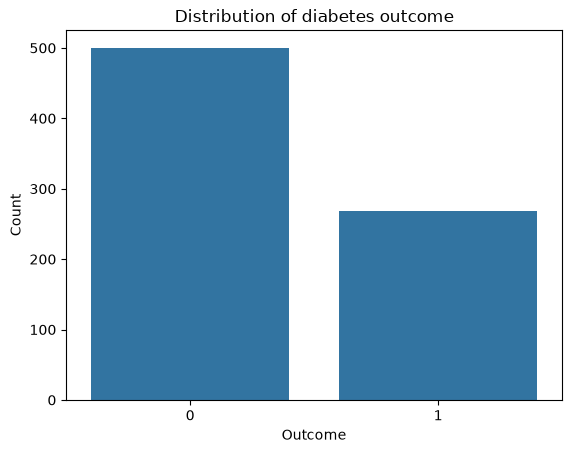

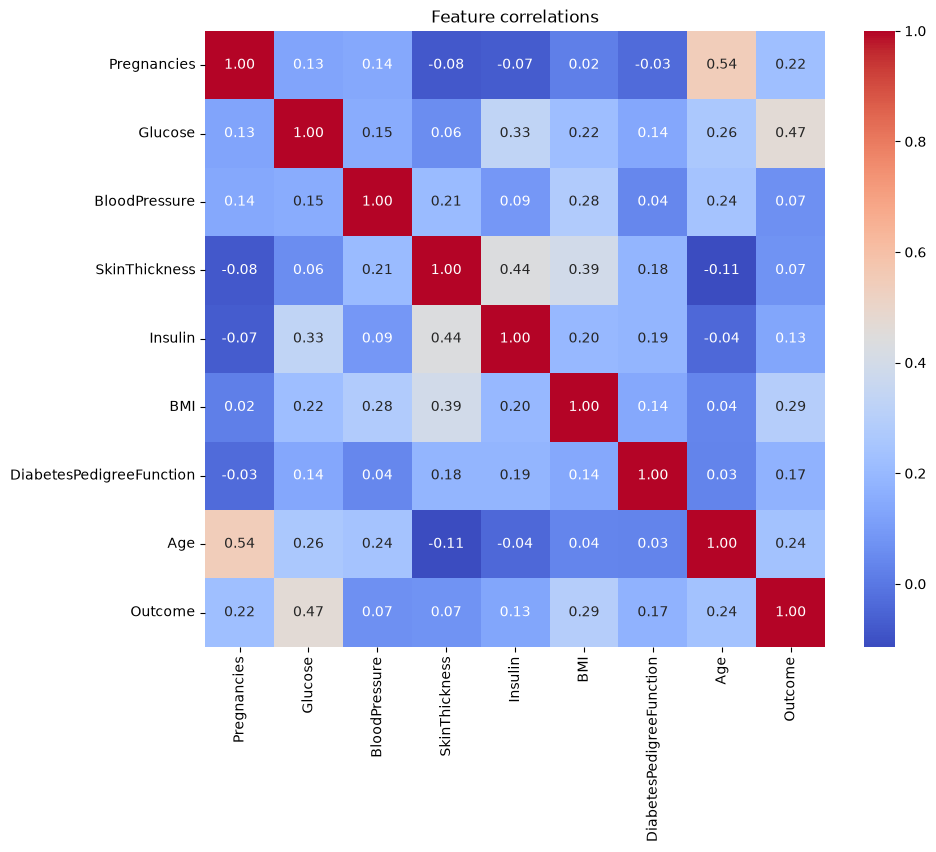

In [5]:
df.describe()
df['Outcome'].value_counts()
sns.countplot(x='Outcome', data=df)
plt.title('Distribution of diabetes outcome')
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.show()

corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature correlations')
plt.show()


#### 3. Split the dataset into labels and features.

In [6]:
X = df.drop(columns=['Outcome'])
y = df['Outcome']


#### 4. Split the dataset into training and test sets (80% and 20%).

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


#### 5. Build a decision tree regressor with some parameters for max depth and min samples, and a criterion of your choice (e.g. squared_error or absolute_error).

In [9]:
model = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42,
    criterion='squared_error'
)
model.fit(X_train, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",4
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

#### 6. Provide predictions for test set.

In [10]:
y_pred = model.predict(X_test)
y_pred_class = (y_pred >= 0.5).astype(int)


print('Predicted values:', y_pred[:10])
print('Classified labels:', y_pred_class[:10])


Predicted values: [1.         0.28787879 0.13836478 0.57943925 0.01834862 0.13836478
 0.28787879 1.         0.13836478 0.83928571]
Classified labels: [1 0 0 1 0 0 0 1 0 1]


#### 7. Evaluate results.

In [12]:
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = metrics.r2_score(y_test, y_pred)

accuracy = metrics.accuracy_score(y_test, y_pred_class)
precision = metrics.precision_score(y_test, y_pred_class, zero_division=0)
recall = metrics.recall_score(y_test, y_pred_class, zero_division=0)
f1 = metrics.f1_score(y_test, y_pred_class, zero_division=0)

print(f'MAE: {mae:.3f}')
print(f'MSE: {mse:.3f}')
print(f'RMSE: {rmse:.3f}')
print(f'R^2: {r2:.3f}')
print(f'Accuracy: {accuracy:.3f}')
print(f'Precision: {precision:.3f}')
print(f'Recall: {recall:.3f}')
print(f'F1: {f1:.3f}')


MAE: 0.306
MSE: 0.171
RMSE: 0.414
R^2: 0.248
Accuracy: 0.786
Precision: 0.706
Recall: 0.667
F1: 0.686


#### 8. Visualize tree.

Use plot_tree to visualize the tree. You can use figsize inside of plt.figure to control the size of the visualization.



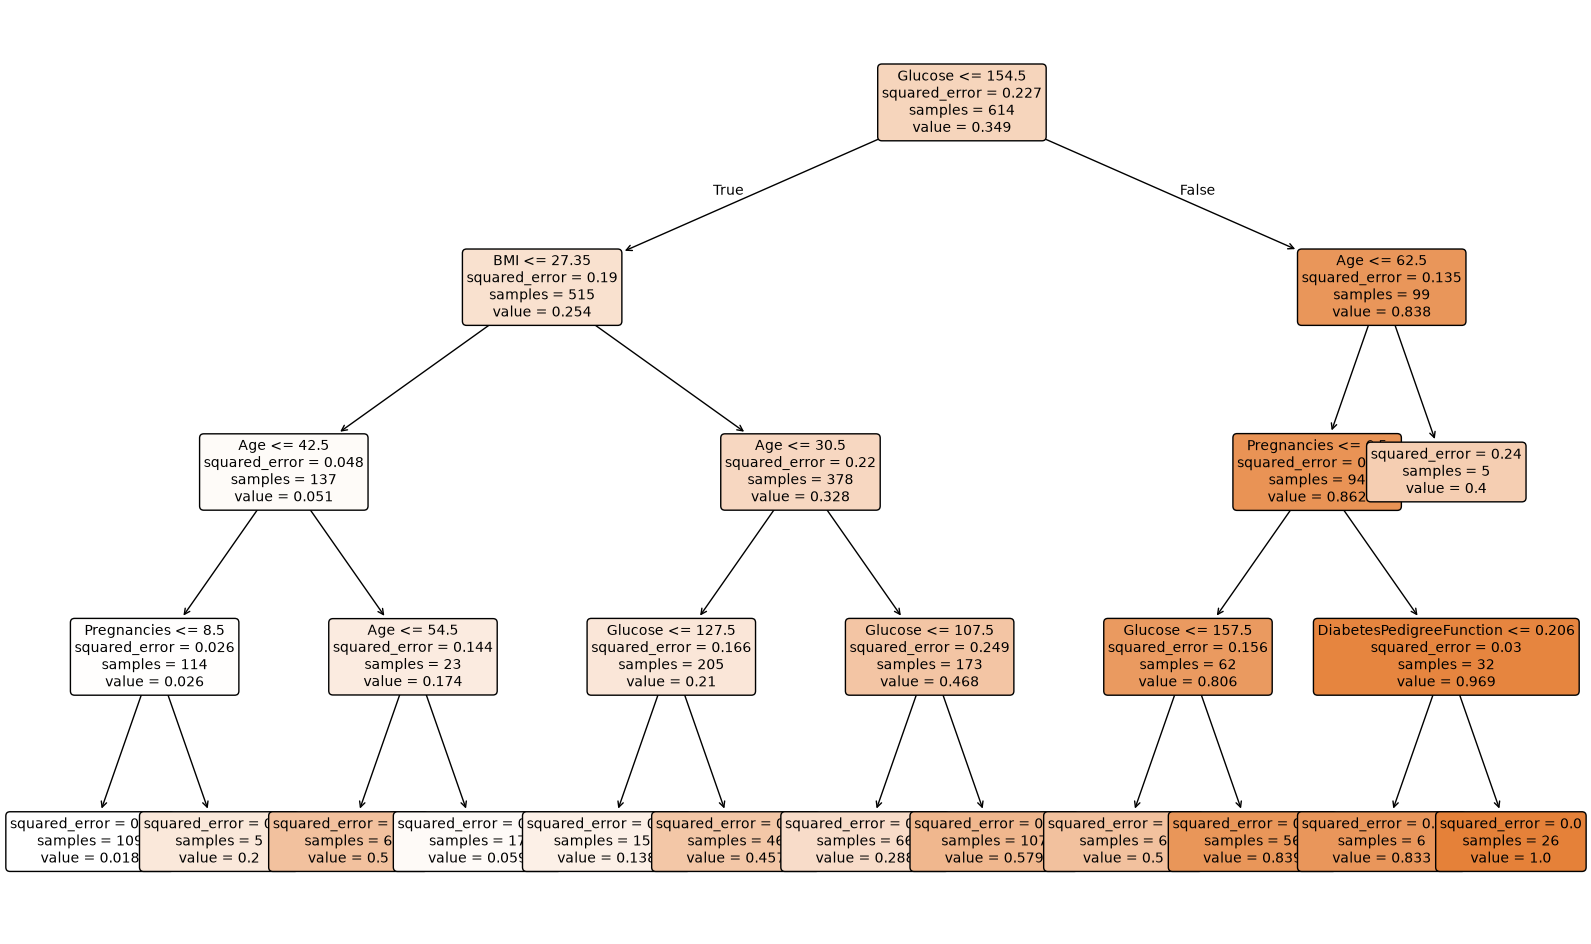

In [13]:
plt.figure(figsize=(20, 12))
plot_tree(model, feature_names=X.columns, filled=True, rounded=True, fontsize=10)

plt.show()


Glucose                     0.677864
Age                         0.161045
BMI                         0.145115
Pregnancies                 0.013429
DiabetesPedigreeFunction    0.002548
BloodPressure               0.000000
SkinThickness               0.000000
Insulin                     0.000000
dtype: float64


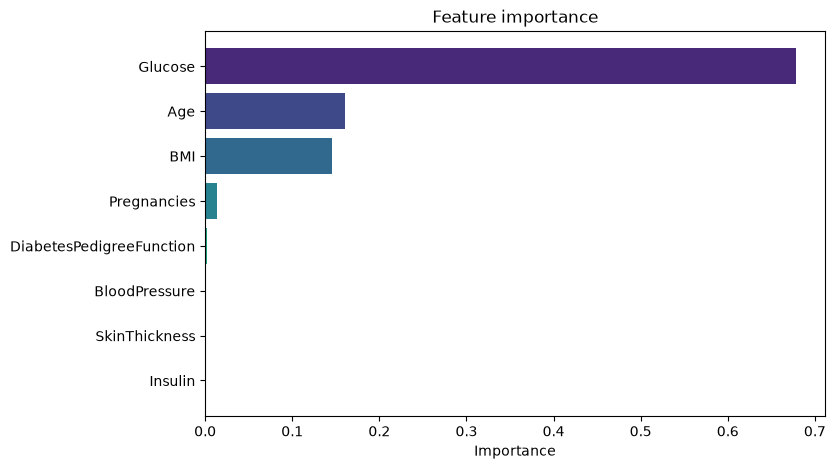

In [14]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

print(importances)


plt.figure(figsize=(8, 5))
colors = sns.color_palette('viridis', len(importances))
plt.barh(importances.index, importances.values, color=colors)
plt.gca().invert_yaxis()
plt.title('Feature importance')
plt.xlabel('Importance')
plt.show()


# FINAL THOUGHTS
- What is the possible benefit of using a regressor instead of a classifier?

  A regressor is useful when we want to predict a number or get a score instead of choosing a class.

- What drawbacks can you imagine when using a regressor to complete a non-binary classification?
  
  A regressor doesn't predict probabilities directly. Need to choose a threshold to turn its result into classes which can be difficult so especially when there two or more classes.


- Which metric do you need to optimize the model for? Accuracy, Precision, Recall, F1? Why?
  
  Recall is very important for diabatese prediction as we need to identify as many people with diabetes as possible also to avoid missing cases and also F1-score is very useful because it balances the Precision and Recall
